In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import glob
import pyblock

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 100,                   # high resolution

    # Axes
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

aa3_to_aa1 = {
    "Ala": "A",
    "Arg": "R",
    "Asn": "N",
    "Asp": "D",
    "Cys": "C",
    "Gln": "Q",
    "Glu": "E",
    "Gly": "G",
    "His": "H",
    "Ile": "I",
    "Leu": "L",
    "Lys": "K",
    "Met": "M",
    "Phe": "F",
    "Pro": "P",
    "Ser": "S",
    "Thr": "T",
    "Trp": "W",
    "Tyr": "Y",
    "Val": "V",
    "Pro_cis": "Pc"
}


tripeptides = ['Ala','Arg','Asn','Asp','Cys','Gln','Glu','Gly','His','Ile','Leu','Lys','Met','Phe','Ser','Thr','Trp','Tyr','Val']


In [11]:

base_path = "../AXA_peptides/"
cutoff = 0.25

df = pd.DataFrame()
df['AA'] = tripeptides

pop_open = []
avg_SASA = []
err_pop_open = []
err_avg_SASA = []
code = []

for aa in tripeptides:
    code.append(aa3_to_aa1[aa])
    filepath = os.path.join(base_path, aa, "SIM", "SASA", "amideH_SASA_traj_fit.npy")
    
    if not os.path.isfile(filepath):
        print(f"Skipping {aa}: DIHEDRALS file not found.")
        continue

    sasa = np.load(filepath) # left, right
    S = sasa[:,1]
        
    avg = np.mean(S)
    fopen = np.mean((S>cutoff)*1, axis=0)

    pop_open.append(fopen)
    avg_SASA.append(avg)

    if fopen ==1.0:
        err_pop_open.append(0.0)
        err_avg_SASA.append(0.0)
        continue

    # errors    
    reblock_data = pyblock.blocking.reblock((S>cutoff)*1)
    opt = pyblock.blocking.find_optimal_block(len(S), reblock_data)[0]
    err_fopen = reblock_data[opt][4]
    reblock_data = pyblock.blocking.reblock(S)
    opt = pyblock.blocking.find_optimal_block(len(S), reblock_data)[0]
    err_avg = reblock_data[opt][4]
    err_pop_open.append(err_fopen)
    err_avg_SASA.append(err_avg)
       

df['fopen'] = np.round(pop_open, 4)
df['fopen ±'] = np.round(err_pop_open, 4)
df['SASA'] = np.round(avg_SASA, 2)
df['SASA ±'] = np.round(err_avg_SASA, 2)
df['aa'] = code

# save
df.to_csv(f'AXA_tripeptides_SASA_cutoff_{cutoff}.csv', index=False)



print(np.mean(df['fopen']))




0.9333526315789475


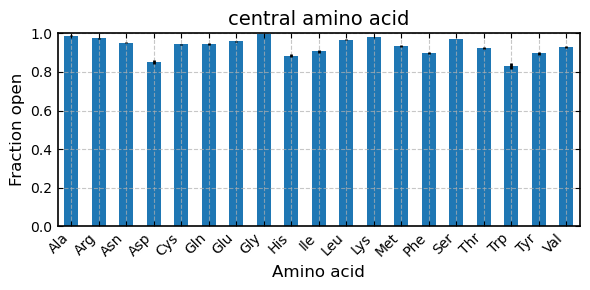

In [12]:

df.plot(x='AA', y='fopen', yerr='fopen ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('Fraction open')
plt.xticks(rotation=45, ha='right')  
plt.title('central amino acid')
plt.ylim(0,1)
plt.tight_layout()
plt.savefig('fraction_open_aa.png')

In [13]:


base_path = "../AXA_peptides/"

# choose SASA cutoffs to scan
cutoffs = np.arange(0.0, 4.05, 0.05)  # Å^2, adjust as needed

rows = []

for cutoff in cutoffs:
    pop_open = []
    err_pop_open = []
    avg_SASA = []
    err_avg_SASA = []
    code = []

    for aa in tripeptides:
        filepath = os.path.join(
            base_path, aa, "SIM", "SASA", "amideH_SASA_traj_fit.npy"
        )

        if not os.path.isfile(filepath):
            print(f"Skipping {aa}: SASA file not found.")
            continue

        code.append(aa3_to_aa1[aa])

        sasa = np.load(filepath)  # left, right
        S = sasa[:, 1]

        open_state = (S > cutoff).astype(float)

        fopen = np.mean(open_state)
        avg = np.mean(S)

        pop_open.append(fopen)
        avg_SASA.append(avg)

        # block errors
        if fopen == 0.0 or fopen == 1.0:
            err_fopen = 0.0
        else:
            reblock_data = pyblock.blocking.reblock(open_state)
            opt = pyblock.blocking.find_optimal_block(len(open_state), reblock_data)[0]
            err_fopen = reblock_data[opt][4]

        reblock_data = pyblock.blocking.reblock(S)
        opt = pyblock.blocking.find_optimal_block(len(S), reblock_data)[0]
        err_avg = reblock_data[opt][4]

        err_pop_open.append(err_fopen)
        err_avg_SASA.append(err_avg)

    pop_open = np.array(pop_open, dtype=float)
    err_pop_open = np.array(err_pop_open, dtype=float)
    avg_SASA = np.array(avg_SASA, dtype=float)

    rows.append({
        "cutoff": cutoff,
        "mean_fopen": np.mean(pop_open),
        "std_fopen": np.std(pop_open, ddof=1),
        "sem_fopen": np.std(pop_open, ddof=1) / np.sqrt(len(pop_open)),
        "mean_SASA": np.mean(avg_SASA),
        "std_SASA": np.std(avg_SASA, ddof=1),
        "n_peptides": len(pop_open),
        "mean_block_error_fopen": np.mean(err_pop_open),
    })

df_cutoff = pd.DataFrame(rows)

df_cutoff.to_csv("AXA_tripeptides_SASA_cutoff_scan.csv", index=False)

print(df_cutoff.head())
print(df_cutoff.tail())

   cutoff  mean_fopen  std_fopen  sem_fopen  mean_SASA  std_SASA  n_peptides  \
0    0.00    0.999258   0.002171   0.000498   5.765712  1.731512          19   
1    0.05    0.948464   0.036923   0.008471   5.765712  1.731512          19   
2    0.10    0.940020   0.041793   0.009588   5.765712  1.731512          19   
3    0.15    0.940016   0.041787   0.009587   5.765712  1.731512          19   
4    0.20    0.933345   0.045560   0.010452   5.765712  1.731512          19   

   mean_block_error_fopen  
0                0.000228  
1                0.003723  
2                0.004231  
3                0.004231  
4                0.004674  
    cutoff  mean_fopen  std_fopen  sem_fopen  mean_SASA  std_SASA  n_peptides  \
76    3.80    0.693347   0.130054   0.029836   5.765712  1.731512          19   
77    3.85    0.685544   0.131636   0.030199   5.765712  1.731512          19   
78    3.90    0.678560   0.133292   0.030579   5.765712  1.731512          19   
79    3.95    0.677715   0.

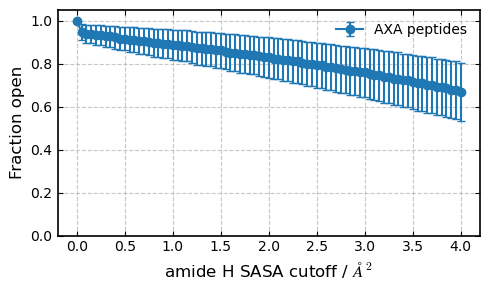

In [14]:
plt.figure(figsize=(5, 3))

plt.errorbar(
    df_cutoff["cutoff"],
    df_cutoff["mean_fopen"],
    yerr=df_cutoff["std_fopen"],
    marker="o",
    capsize=3,
    linewidth=1.5,
    label="AXA peptides"
)

plt.xlabel(r"amide H SASA cutoff / $\AA^2$")
plt.ylabel("Fraction open")
plt.xscale("linear")
plt.ylim(0, 1.05)
plt.legend(frameon=False)
plt.tight_layout()

plt.savefig(
    "SASA_cutoff_vs_fopen_avg_AXA_peptides.png",
    dpi=300
)
plt.show()

In [95]:

base_path = "../AXA_peptides/"
cutoff = 0.05

df = pd.DataFrame()
df['AA'] = tripeptides

pop_open = []
avg_SASA = []
err_pop_open = []
err_avg_SASA = []
code = []

for aa in tripeptides:
    code.append(aa3_to_aa1[aa])
    filepath = os.path.join(base_path, aa, "SIM", "SASA", "amideH_SASA_traj_fit.npy")
    
    if not os.path.isfile(filepath):
        print(f"Skipping {aa}: DIHEDRALS file not found.")
        continue

    sasa = np.load(filepath) # left, right
    S = sasa[:,2] # Ala after (amide to the right of the sidechain)
        
    avg = np.mean(S)
    fopen = np.mean((S>cutoff)*1, axis=0)

    pop_open.append(fopen)
    avg_SASA.append(avg)

    if fopen ==1.0:
        err_pop_open.append(0.0)
        err_avg_SASA.append(0.0)
        continue

    # errors    
    reblock_data = pyblock.blocking.reblock((S>cutoff)*1)
    opt = pyblock.blocking.find_optimal_block(len(S), reblock_data)[0]
    err_fopen = reblock_data[opt][4]
    reblock_data = pyblock.blocking.reblock(S)
    opt = pyblock.blocking.find_optimal_block(len(S), reblock_data)[0]
    err_avg = reblock_data[opt][4]
    err_pop_open.append(err_fopen)
    err_avg_SASA.append(err_avg)
       

df['fopen'] = np.round(pop_open, 4)
df['fopen ±'] = np.round(err_pop_open, 4)
df['SASA'] = np.round(avg_SASA, 2)
df['SASA ±'] = np.round(err_avg_SASA, 2)
df['aa'] = code

# save
df.to_csv(f'AXA_tripeptides_Raa_SASA_cutoff_{cutoff}.csv', index=False)








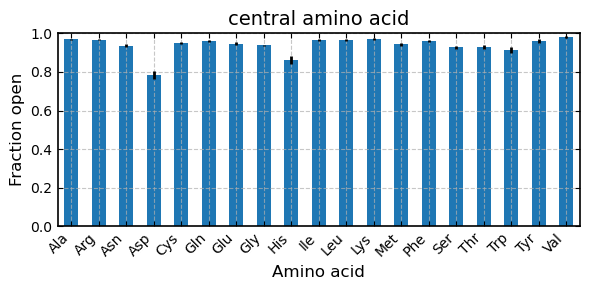

In [96]:

df.plot(x='AA', y='fopen', yerr='fopen ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('Fraction open')
plt.xticks(rotation=45, ha='right')  
plt.title('central amino acid')
plt.ylim(0,1)
plt.tight_layout()
plt.savefig('fraction_open_aa_Raa.png')

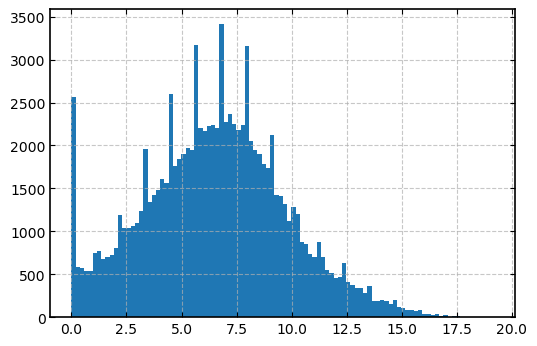

In [24]:
sasa = np.load('../AXA_peptides/Arg/SIM/SASA/amideH_SASA_traj_fit.npy')[:,1]
plt.hist(sasa, bins=100)
plt.show()

In [25]:
np.min(sasa)

0.0

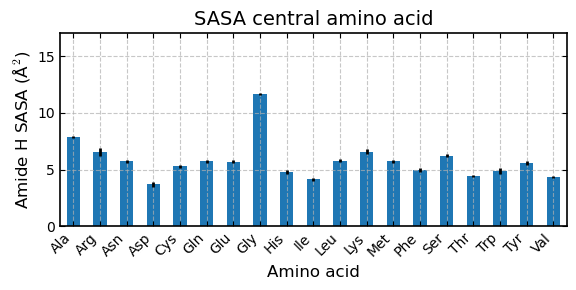

In [4]:

df.plot(x='AA', y='SASA', yerr='SASA ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('Amide H SASA (Å$^2$)')
plt.xticks(rotation=45, ha='right')    
plt.title('SASA central amino acid')
plt.ylim(0,17)
plt.tight_layout()
plt.savefig('SASA_aa.png')

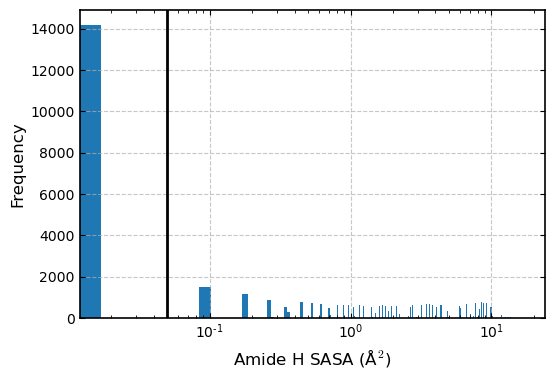

In [67]:
sasa = np.load('../AXA_peptides/Trp/SIM/SASA/amideH_SASA_traj_fit.npy')[:,1]

plt.hist(sasa, bins=1000)
plt.axvline(0.05, color='black')
plt.xlabel('Amide H SASA (Å$^2$)')
plt.ylabel('Frequency')
plt.xscale('log')

In [68]:
sasa[np.where(sasa<0.2)[0]]

array([8.8887326e-02, 6.2648236e-04, 5.5436288e-07, ..., 3.9150799e-04,
       3.4643836e-07, 9.1072142e-02], dtype=float32)

/tmp/ipykernel_490471/269309528.py:4: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  plt.ylim(0,1e0)


(0.03736859540328541, 1.0)

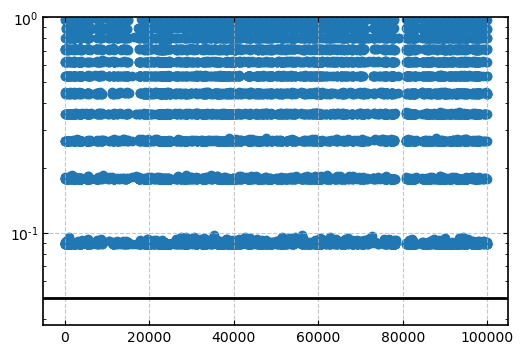

In [69]:
plt.scatter(np.arange(len(sasa)), sasa)
plt.yscale('log')
plt.axhline(0.05, color='black')
plt.ylim(0,1e0)

In [70]:
for cut in [0.01, 0.02, 0.05, 0.075, 0.1, 0.15, 0.2, 0.5, 1.0]:
    print(f"Cutoff: {cut}, Fraction open: {np.mean((sasa>cut)*1):.4f}")



Cutoff: 0.01, Fraction open: 0.8581
Cutoff: 0.02, Fraction open: 0.8580
Cutoff: 0.05, Fraction open: 0.8580
Cutoff: 0.075, Fraction open: 0.8580
Cutoff: 0.1, Fraction open: 0.8432
Cutoff: 0.15, Fraction open: 0.8432
Cutoff: 0.2, Fraction open: 0.8317
Cutoff: 0.5, Fraction open: 0.8063
Cutoff: 1.0, Fraction open: 0.7668


(0.0, 1.0)

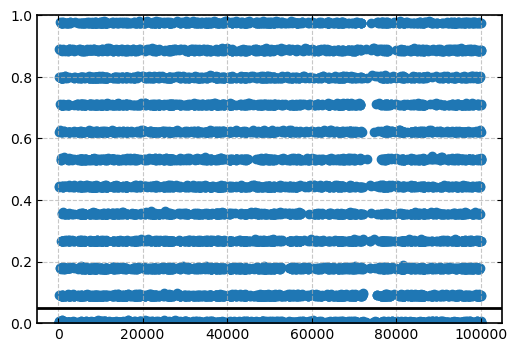

In [59]:
plt.scatter(np.arange(len(sasa)), sasa)
plt.axhline(0.05, color='black')
plt.ylim(0,1)

In [77]:
SASA = np.load('../../MD_DATA/Ubiquitin/SASA/amideH_SASA_traj10.npy')
res = np.loadtxt('../../MD_DATA/Ubiquitin/SASA/amideresidues.txt')
SASA.shape

(20001, 73)

In [92]:
RES = 36
idx = np.where(res==RES)[0][0]

for cut in [0.01, 0.02, 0.05, 0.075, 0.1, 0.15, 0.2, 0.5, 1.0, 4.0]:
    print(f"Cutoff: {cut}, Fraction open: {np.mean((SASA[:,idx]>cut)*1):.4f}")



Cutoff: 0.01, Fraction open: 0.0114
Cutoff: 0.02, Fraction open: 0.0114
Cutoff: 0.05, Fraction open: 0.0114
Cutoff: 0.075, Fraction open: 0.0114
Cutoff: 0.1, Fraction open: 0.0073
Cutoff: 0.15, Fraction open: 0.0073
Cutoff: 0.2, Fraction open: 0.0051
Cutoff: 0.5, Fraction open: 0.0023
Cutoff: 1.0, Fraction open: 0.0007
Cutoff: 4.0, Fraction open: 0.0000


In [94]:


for cut in [0.01, 0.02, 0.05, 0.075, 0.1, 0.15, 0.2, 0.5, 1.0, 4.0]:
    print(f"Cutoff: {cut}, Fraction open: {np.mean((SASA.flatten()>cut)*1):.4f}")



Cutoff: 0.01, Fraction open: 0.3298
Cutoff: 0.02, Fraction open: 0.3293
Cutoff: 0.05, Fraction open: 0.3293
Cutoff: 0.075, Fraction open: 0.3293
Cutoff: 0.1, Fraction open: 0.3173
Cutoff: 0.15, Fraction open: 0.3172
Cutoff: 0.2, Fraction open: 0.3087
Cutoff: 0.5, Fraction open: 0.2895
Cutoff: 1.0, Fraction open: 0.2608
Cutoff: 4.0, Fraction open: 0.1620


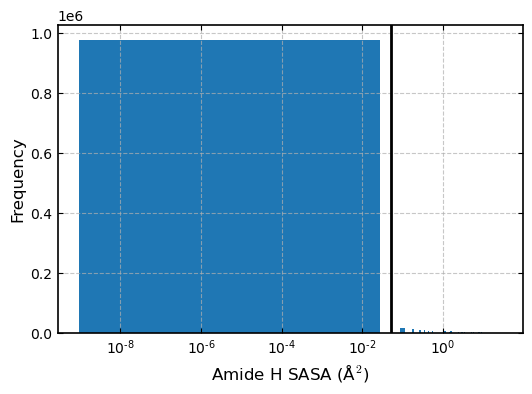

In [93]:


plt.hist(SASA.flatten(), bins=1000)
plt.axvline(0.05, color='black')
plt.xlabel('Amide H SASA (Å$^2$)')
plt.ylabel('Frequency')
plt.xscale('log')